In [1]:
import numpy as np
from scipy.interpolate import CubicSpline

x = np.array([0, 1, 2, 3, 4])
y = np.array([0, 1, 1, 2, 2])

def solve_spline(x, y):
    return CubicSpline(x, y, bc_type="not-a-knot")

s = solve_spline(x, y)

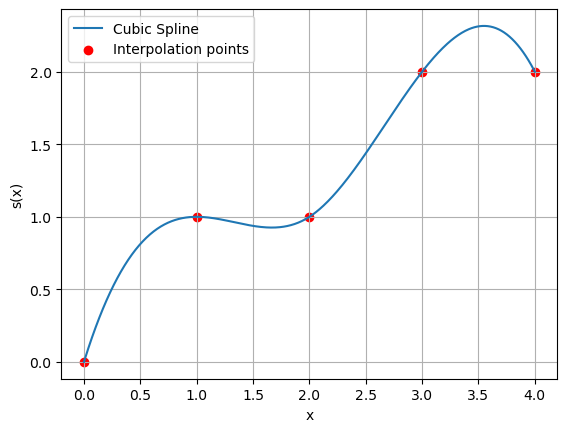

In [2]:
import matplotlib.pyplot as plt

xx = np.linspace(0, 4, 500)

plt.plot(xx, s(xx), label="Cubic Spline")
plt.scatter(x, y, color="red", label="Interpolation points")

plt.xlabel("x")
plt.ylabel("s(x)")
plt.legend()
plt.grid()
plt.show()

In [3]:
from numpy.polynomial import Polynomial

for j in range(len(x) - 1):
    p = Polynomial(s.c[:, j][::-1])
    p = p(Polynomial([-x[j], 1]))

    print(f"s_{j}(x) = {p}")
    print(f"Intervall: [{x[j]}, {x[j+1]}]\n")

s_0(x) = 0.0 + 2.5 x - 2.0 x**2 + 0.5 x**3
Intervall: [0, 1]

s_1(x) = 0.0 + 2.5 x - 2.0 x**2 + 0.5 x**3
Intervall: [1, 2]

s_2(x) = 8.0 - 9.5 x + 4.0 x**2 - 0.5 x**3
Intervall: [2, 3]

s_3(x) = 8.0 - 9.5 x + 4.0 x**2 - 0.5 x**3
Intervall: [3, 4]



In [4]:
import sympy as sp

x = sp.symbols("x")
a = sp.symbols("a0:4")
b = sp.symbols("b0:4")
c = sp.symbols("c0:4")
d = sp.symbols("d0:4")

s = [a[j] + b[j]*x + c[j]*x**2 + d[j]*x**3 for j in range(4)]

# 8 Interpolationsbedingungen
eqs = [
    sp.Eq(a[0], 0),
    sp.Eq(a[0]+b[0]+c[0]+d[0], 1),
    sp.Eq(a[1]+b[1]+c[1]+d[1], 1),
    sp.Eq(a[1]+2*b[1]+4*c[1]+8*d[1], 1),
    sp.Eq(a[2]+2*b[2]+4*c[2]+8*d[2], 1),
    sp.Eq(a[2]+3*b[2]+9*c[2]+27*d[2], 2),
    sp.Eq(a[3]+3*b[3]+9*c[3]+27*d[3], 2),
    sp.Eq(a[3]+4*b[3]+16*c[3]+64*d[3], 2)
]

# 6 Stetigkeitsbedingungen (1. und 2. Ableitung)
for j in range(1, 4):
    eqs.append(sp.Eq(sp.diff(s[j-1], x).subs(x, j),
                     sp.diff(s[j], x).subs(x, j)))
    eqs.append(sp.Eq(sp.diff(s[j-1], x, 2).subs(x, j),
                     sp.diff(s[j], x, 2).subs(x, j)))

# 2 Not-a-knot-Bedingungen
eqs += [sp.Eq(d[0], d[1]), sp.Eq(d[2], d[3])]

# Lineares Gleichungssystem lösen
variables = [v for j in range(4) for v in (a[j], b[j], c[j], d[j])]
solution = sp.solve(eqs, variables, dict=True)[0]

# Explizite Polynome ausgeben
for j in range(4):
    print(f"s_{j}(x) =", sp.expand(s[j].subs(solution)))
    print(f"Intervall: [{j}, {j+1}]\n")

s_0(x) = x**3/2 - 2*x**2 + 5*x/2
Intervall: [0, 1]

s_1(x) = x**3/2 - 2*x**2 + 5*x/2
Intervall: [1, 2]

s_2(x) = -x**3/2 + 4*x**2 - 19*x/2 + 8
Intervall: [2, 3]

s_3(x) = -x**3/2 + 4*x**2 - 19*x/2 + 8
Intervall: [3, 4]



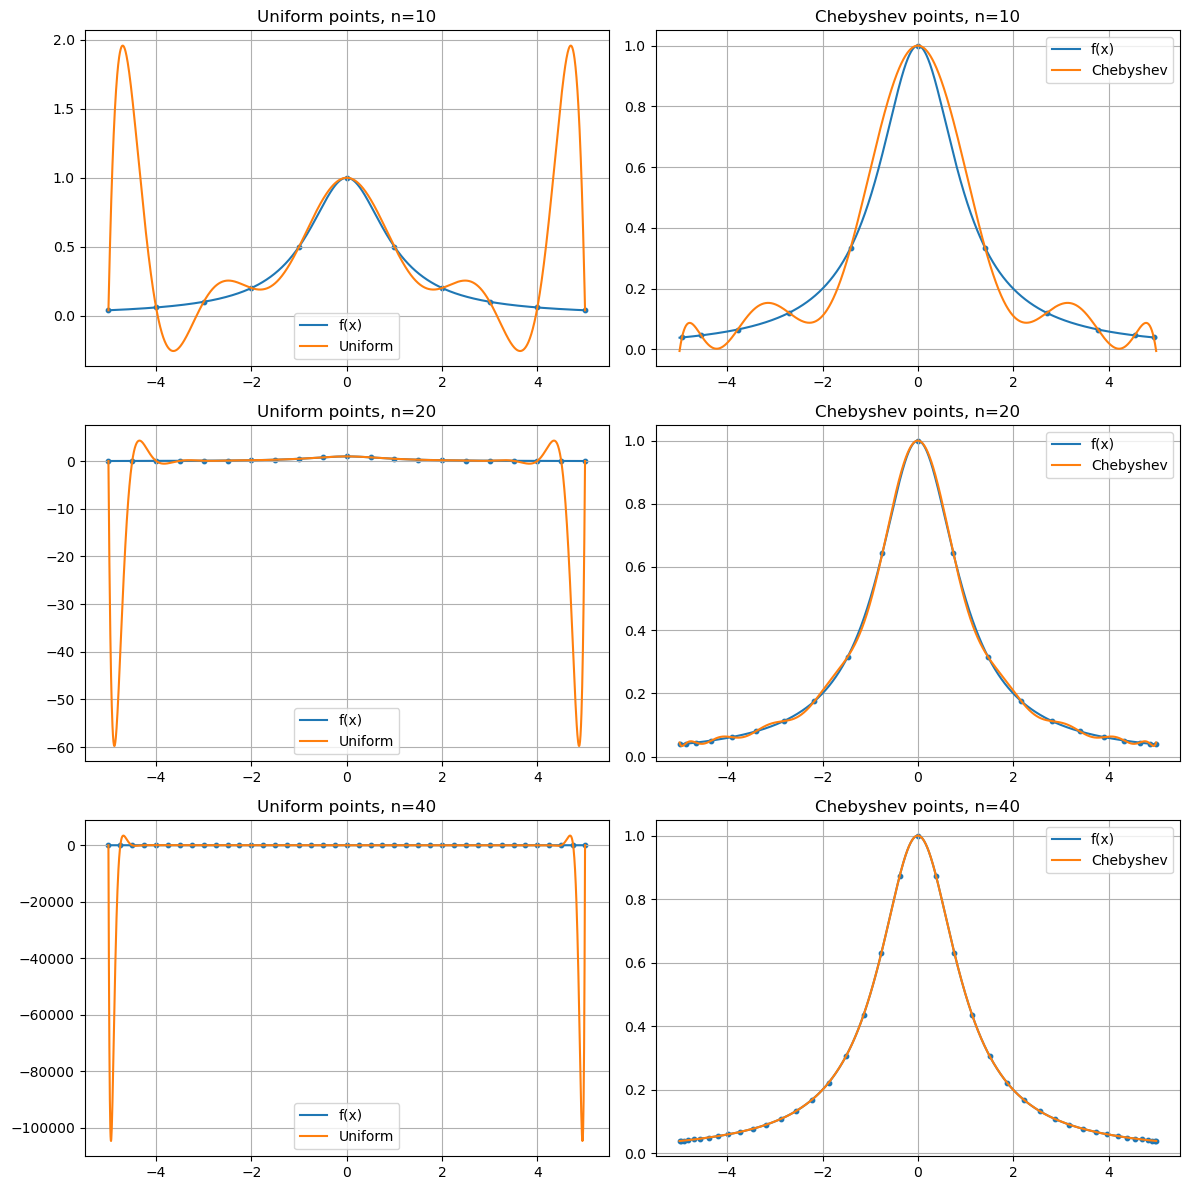

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator

def f(x):
    return 1 / (1 + x**2)

xx = np.linspace(-5, 5, 2000)
ns = [10, 20, 40]

fig, axes = plt.subplots(3, 2, figsize=(12, 12))

for j, n in enumerate(ns):
    i = np.arange(n + 1)

    # Interpolation points
    x_unif = 5 * (-1 + 2*i/n)
    x_cheb = 5 * np.cos((i + 0.5)*np.pi/(n + 1))

    # Interpolation polynomials
    p_unif = BarycentricInterpolator(x_unif, f(x_unif))
    p_cheb = BarycentricInterpolator(x_cheb, f(x_cheb))

    # Uniform points
    axes[j, 0].plot(xx, f(xx), label="f(x)")
    axes[j, 0].plot(xx, p_unif(xx), label="Uniform")
    axes[j, 0].scatter(x_unif, f(x_unif), s=10)
    axes[j, 0].set_title(f"Uniform points, n={n}")
    axes[j, 0].legend()
    axes[j, 0].grid()

    # Chebyshev points
    axes[j, 1].plot(xx, f(xx), label="f(x)")
    axes[j, 1].plot(xx, p_cheb(xx), label="Chebyshev")
    axes[j, 1].scatter(x_cheb, f(x_cheb), s=10)
    axes[j, 1].set_title(f"Chebyshev points, n={n}")
    axes[j, 1].legend()
    axes[j, 1].grid()

plt.tight_layout()
plt.show()

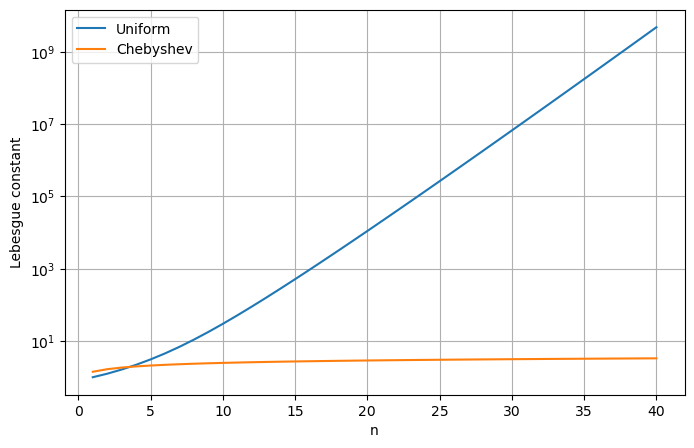

n=10: Uniform=2.989995e+01, Chebyshev=2.489430
n=20: Uniform=1.098666e+04, Chebyshev=2.900825
n=40: Uniform=4.692431e+09, Chebyshev=3.326682


In [ ]:
# Numerical computation of Lebesgue constants

xx = np.linspace(-5, 5, 10001)
ns = np.arange(1, 41)

def lebesgue_constant(nodes):
    # Compute all Lagrange basis polynomials
    L = BarycentricInterpolator(nodes, np.eye(len(nodes)))
    # Each column of the identity matrix defines the interpolation values
    # of one Lagrange basis polynomial (1 at its own node, 0 at all others).    
    # L(xx) evaluates all these polynomials at the points in xx.

    # Lebesgue function and its maximum
    return np.max(np.sum(np.abs(L(xx)), axis=1))

lambda_unif = []
lambda_cheb = []

for n in ns:
    i = np.arange(n + 1)

    x_unif = 5 * (-1 + 2*i/n)
    x_cheb = 5 * np.cos((i + 0.5)*np.pi/(n + 1))

    lambda_unif.append(lebesgue_constant(x_unif))
    lambda_cheb.append(lebesgue_constant(x_cheb))

plt.figure(figsize=(8, 5))
plt.semilogy(ns, lambda_unif, label="Uniform")
plt.semilogy(ns, lambda_cheb, label="Chebyshev")

plt.xlabel("n")
plt.ylabel("Lebesgue constant")
plt.legend()
plt.grid()
plt.show()

# Values needed for part c)
for n in [10, 20, 40]:
    print(f"n={n}: Uniform={lambda_unif[n-1]:.6e}, "
          f"Chebyshev={lambda_cheb[n-1]:.6f}")

### 3.3 c) Exponential Growth of the Lebesgue Constant

We assume that

$$
\Lambda_n \approx C e^{bn}.
$$

Taking the logarithm gives

$$
\log(\Lambda_n) \approx \log(C) + bn.
$$

Using the values for $n=20$ and $n=40$:

$$
\begin{aligned}
\log(\Lambda_{20}) &= \log(C) + 20b,\\
\log(\Lambda_{40}) &= \log(C) + 40b.
\end{aligned}
$$

Subtracting both equations yields

$$
b = \frac{\log(\Lambda_{40})-\log(\Lambda_{20})}{20}.
$$

Substituting back:

$$
C = \exp\left(\log(\Lambda_{20})-20b\right).
$$

Thus, $C$ and $b$ can be determined from the numerical
Lebesgue constants computed in part (b).

In [9]:
L20 = lambda_unif[19]
L40 = lambda_unif[39]

b = (np.log(L40) - np.log(L20)) / 20
C = np.exp(np.log(L20) - 20*b)

print(f"C = {C:.6f}")
print(f"b = {b:.6f}")

C = 0.025724
b = 0.648239


In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Function from 3.4 (a) and (b)
def f(x):
    return np.cos(np.pi*x) + 0.25*np.cos(3*np.pi*x)

def f_prime(x):
    return -np.pi*np.sin(np.pi*x) - 0.75*np.pi*np.sin(3*np.pi*x)

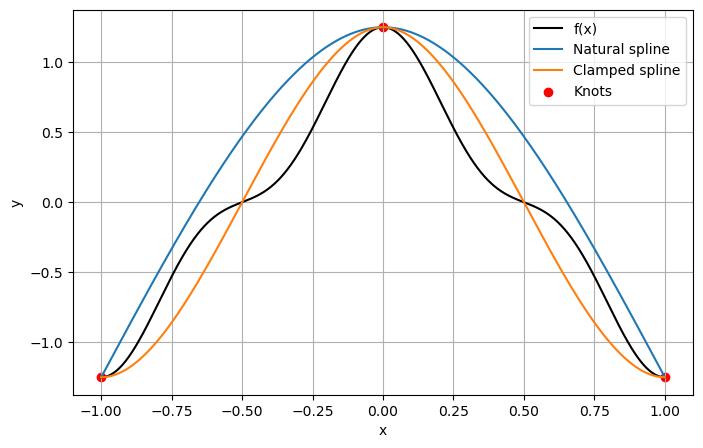

In [11]:
x = np.array([-1., 0., 1.])
y = f(x)

s_nat = CubicSpline(x, y, bc_type="natural")

s_cl = CubicSpline(
    x, y,
    bc_type=((1, f_prime(-1)), (1, f_prime(1)))
)

xx = np.linspace(-1, 1, 2000)

plt.figure(figsize=(8, 5))
plt.plot(xx, f(xx), label="f(x)", color="black")
plt.plot(xx, s_nat(xx), label="Natural spline")
plt.plot(xx, s_cl(xx), label="Clamped spline")
plt.scatter(x, y, color="red", label="Knots")

plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid()
plt.show()

In [12]:
xx = np.linspace(-1, 1, 10001)

error_nat = np.max(np.abs(f(xx) - s_nat(xx)))
error_cl = np.max(np.abs(f(xx) - s_cl(xx)))

print(f"Natural spline error: {error_nat:.8f}")
print(f"Clamped spline error: {error_cl:.8f}")

Natural spline error: 0.63872760
Clamped spline error: 0.36031328


In [13]:
def g(x):
    return np.exp(-100*(x - 1/5)**2) + np.sin(6*np.pi*x)

def g_prime(x):
    return (-200*(x - 1/5)*np.exp(-100*(x - 1/5)**2)
            + 6*np.pi*np.cos(6*np.pi*x))

ns = [8, 16, 32, 64, 128, 256]
xx = np.linspace(0, 1, 10001)

errors_nat = []
errors_cl = []
splines = {}

for n in ns:
    x = np.linspace(0, 1, n + 1)
    y = g(x)

    s_nat = CubicSpline(x, y, bc_type="natural")
    s_cl = CubicSpline(
        x, y,
        bc_type=((1, g_prime(0)), (1, g_prime(1)))
    )

    errors_nat.append(np.max(np.abs(g(xx) - s_nat(xx))))
    errors_cl.append(np.max(np.abs(g(xx) - s_cl(xx))))

    splines[n] = (s_nat, s_cl)

for n, en, ec in zip(ns, errors_nat, errors_cl):
    print(f"n={n:3d} | Natural={en:.6e} | Clamped={ec:.6e}")

n=  8 | Natural=2.764012e-01 | Clamped=2.777306e-01
n= 16 | Natural=1.291382e-02 | Clamped=1.290957e-02
n= 32 | Natural=1.031252e-03 | Clamped=4.680162e-04
n= 64 | Natural=2.987722e-04 | Clamped=2.725278e-05
n=128 | Natural=7.639563e-05 | Clamped=1.669706e-06
n=256 | Natural=1.918295e-05 | Clamped=1.037830e-07


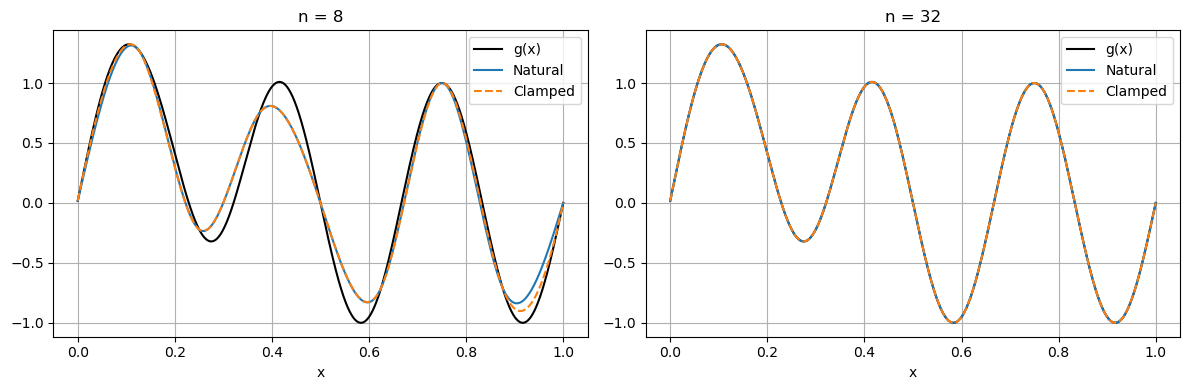

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, n in zip(axes, [8, 32]):
    s_nat, s_cl = splines[n]

    ax.plot(xx, g(xx), label="g(x)", color="black")
    ax.plot(xx, s_nat(xx), label="Natural")
    ax.plot(xx, s_cl(xx), label="Clamped", linestyle="--")

    ax.set_title(f"n = {n}")
    ax.set_xlabel("x")
    ax.legend()
    ax.grid()

plt.tight_layout()
plt.show()

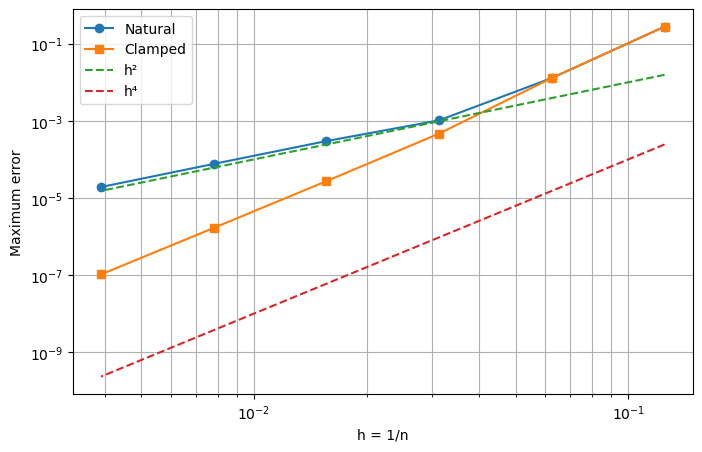

  8 ->  16: Natural=4.420, Clamped=4.427
 16 ->  32: Natural=3.646, Clamped=4.786
 32 ->  64: Natural=1.787, Clamped=4.102
 64 -> 128: Natural=1.967, Clamped=4.029
128 -> 256: Natural=1.994, Clamped=4.008


In [15]:
h = 1 / np.array(ns, dtype=float)

plt.figure(figsize=(8, 5))

plt.loglog(h, errors_nat, "o-", label="Natural")
plt.loglog(h, errors_cl, "s-", label="Clamped")

# Reference convergence rates
plt.loglog(h, h**2, "--", label="h²")
plt.loglog(h, h**4, "--", label="h⁴")

plt.xlabel("h = 1/n")
plt.ylabel("Maximum error")
plt.legend()
plt.grid(True, which="both")
plt.show()

# Experimental convergence rates
for i in range(1, len(ns)):
    rate_nat = np.log2(errors_nat[i-1] / errors_nat[i])
    rate_cl = np.log2(errors_cl[i-1] / errors_cl[i])

    print(f"{ns[i-1]:3d} -> {ns[i]:3d}: "
          f"Natural={rate_nat:.3f}, Clamped={rate_cl:.3f}")